# E-commerce Analysis


## 1. Load

In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})

DATA = Path("data")
PRICE_INCREASE_DATE = pd.Timestamp("2025-01-01")
PRICE_INCREASE = 1.05
FREE_SHIPPING_MIN = 75
SHIPPING_FEE = 6.95
POWER_MIN_ORDERS = 15

customers = pd.read_csv(DATA / "customers.csv", parse_dates=["signup_date"])
orders = pd.read_csv(DATA / "orders.csv", parse_dates=["order_date"])
items = pd.read_csv(DATA / "order_items.csv")
products = pd.read_csv(DATA / "products.csv")

pd.DataFrame(
    {"rows": [len(t) for t in (customers, orders, items, products)]},
    index=["customers", "orders", "order_items", "products"],
)

,rows
customers,3600
orders,9245
order_items,15608
products,90


## 2. Clean

In [ ]:
duplicates = orders.duplicated().sum()
orders = orders.drop_duplicates().reset_index(drop=True)
assert orders["order_id"].is_unique

products["category"] = products["category"].str.strip().str.title()

lines = (
    items.merge(products, on="product_id")
    .merge(orders, on="order_id")
    .merge(customers, on="customer_id")
)

price_factor = np.where(lines["order_date"] >= PRICE_INCREASE_DATE, PRICE_INCREASE, 1.0)
expected_price = (lines["list_price"] * price_factor).round(2)
known_price = lines["unit_price"].notna()
assert np.allclose(lines.loc[known_price, "unit_price"], expected_price[known_price], atol=0.011)
missing_prices = (~known_price).sum()
lines["unit_price"] = lines["unit_price"].fillna(expected_price)

print(f"duplicate orders removed: {duplicates}")
print(f"missing prices rebuilt:   {missing_prices}")
print(f"categories:               {products['category'].nunique()}")

duplicate orders removed: 38
missing prices rebuilt:   199
categories:               8


In [ ]:
lines["gross"] = lines["quantity"] * lines["unit_price"]
lines["net"] = lines["gross"] - lines["discount_amount"]
lines["cost"] = lines["quantity"] * lines["unit_cost"]

completed_line = lines["status"] == "completed"
lines["revenue"] = lines["net"].where(completed_line, 0.0)
lines["profit"] = (lines["net"] - lines["cost"]).where(completed_line, 0.0)
lines["returned_value"] = lines["net"].where(lines["status"] == "returned", 0.0)
lines["year"] = lines["order_date"].dt.year

order_totals = lines.groupby("order_id").agg(
    gross=("gross", "sum"),
    discount=("discount_amount", "sum"),
    net=("net", "sum"),
    cost=("cost", "sum"),
)
orders = orders.merge(order_totals, on="order_id").sort_values(["customer_id", "order_date", "order_id"])
orders["is_first_order"] = ~orders.duplicated("customer_id")
orders["year"] = orders["order_date"].dt.year

## 3. Validate

In [ ]:
expected_fee = np.where(orders["net"] < FREE_SHIPPING_MIN - 0.005, SHIPPING_FEE, 0.0)
signup = orders["customer_id"].map(customers.set_index("customer_id")["signup_date"])

checks = {
    "unique customers": customers["customer_id"].is_unique,
    "unique products": products["product_id"].is_unique,
    "unique order lines": not lines.duplicated(["order_id", "product_id"]).any(),
    "orders have customers": orders["customer_id"].isin(customers["customer_id"]).all(),
    "items have orders": items["order_id"].isin(orders["order_id"]).all(),
    "items have products": items["product_id"].isin(products["product_id"]).all(),
    "orders have items": orders["order_id"].isin(items["order_id"]).all(),
    "no missing prices": lines["unit_price"].notna().all(),
    "positive quantities": (lines["quantity"] > 0).all(),
    "shipping rule": np.allclose(orders["shipping_fee"], expected_fee),
    "no order before signup": (orders["order_date"].dt.normalize() >= signup).all(),
}
assert all(checks.values()), [name for name, ok in checks.items() if not ok]
print(f"{len(checks)} of {len(checks)} checks passed")

11 of 11 checks passed


## 4. Performance

In [ ]:
completed = lines[completed_line]
completed_orders = completed["order_id"].nunique()
revenue = lines["revenue"].sum()
profit = lines["profit"].sum()
non_canceled = orders[orders["status"] != "canceled"]
order_return_rate = (non_canceled["status"] == "returned").mean()

pd.Series({
    "Net revenue": revenue,
    "Gross profit": profit,
    "Gross margin": profit / revenue,
    "Completed orders": completed_orders,
    "Average order value": revenue / completed_orders,
    "Return rate (orders)": order_return_rate,
}).round(3).to_frame("value")

,value
Net revenue,1881974.280
Gross profit,925948.260
Gross margin,0.492
Completed orders,8456.000
Average order value,222.561
Return rate (orders),0.046


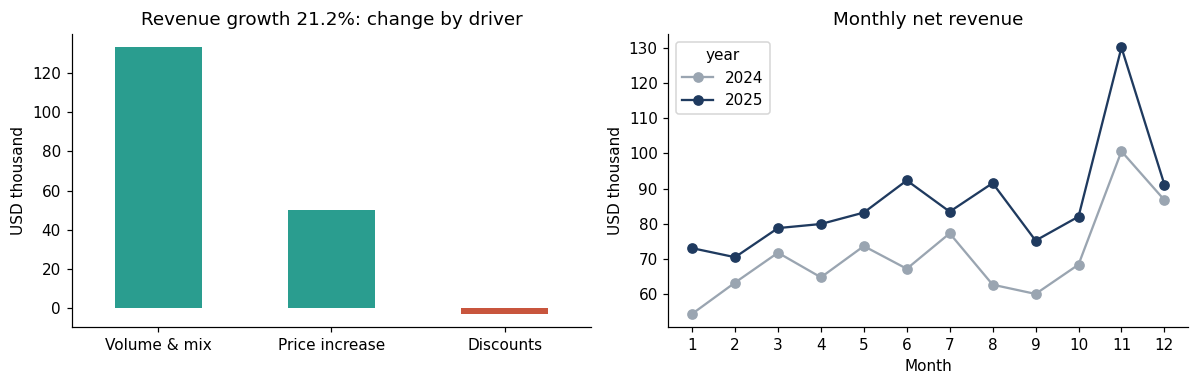

In [ ]:
by_year = completed.groupby("year").agg(
    gross=("gross", "sum"), discount=("discount_amount", "sum"), revenue=("revenue", "sum")
)
gross_2025_at_old_prices = by_year.loc[2025, "gross"] / PRICE_INCREASE

bridge = pd.Series({
    "Volume & mix": gross_2025_at_old_prices - by_year.loc[2024, "gross"],
    "Price increase": by_year.loc[2025, "gross"] - gross_2025_at_old_prices,
    "Discounts": -(by_year.loc[2025, "discount"] - by_year.loc[2024, "discount"]),
})
growth = by_year.loc[2025, "revenue"] / by_year.loc[2024, "revenue"] - 1
assert np.isclose(bridge.sum(), by_year.loc[2025, "revenue"] - by_year.loc[2024, "revenue"])

monthly = lines.groupby(["year", lines["order_date"].dt.month])["revenue"].sum().unstack(0) / 1000

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
bridge.div(1000).plot.bar(ax=axes[0], color=["#2A9D8F", "#2A9D8F", "#C8553D"], rot=0)
axes[0].set(title=f"Revenue growth {growth:.1%}: change by driver", ylabel="USD thousand")
monthly.plot(ax=axes[1], marker="o", color=["#9AA5B1", "#1F3A5F"])
axes[1].set(title="Monthly net revenue", xlabel="Month", ylabel="USD thousand", xticks=range(1, 13))
plt.tight_layout()

## 5. Categories and returns

In [ ]:
category = lines.groupby("category").agg(
    revenue=("revenue", "sum"), profit=("profit", "sum"), returned=("returned_value", "sum")
)
category["margin"] = category["profit"] / category["revenue"]
category["return_rate"] = category["returned"] / (category["revenue"] + category["returned"])
category["revenue_share"] = category["revenue"] / category["revenue"].sum()
category["returned_share"] = category["returned"] / category["returned"].sum()
category = category.sort_values("return_rate", ascending=False)

lines_kept = lines[lines["status"] != "canceled"]
is_furniture = lines_kept["category"] == "Furniture"
is_returned = lines_kept["status"] == "returned"
furniture_p = stats.chi2_contingency(pd.crosstab(is_furniture, is_returned))[1]
line_return_rate = is_returned.groupby(is_furniture).mean()

print(f"furniture line return rate: {line_return_rate[True]:.1%} vs {line_return_rate[False]:.1%} elsewhere (p = {furniture_p:.1e})")
category.round(3)

furniture line return rate: 12.1% vs 4.6% elsewhere (p = 9.8e-26)


,revenue,profit,returned,margin,return_rate,revenue_share,returned_share
category,,,,,,,
Furniture,322848.81,149055.17,38668.52,0.462,0.107,0.172,0.331
Outdoor,247750.78,123773.91,14502.35,0.500,0.055,0.132,0.124
Bedding,267025.16,136663.04,15526.35,0.512,0.055,0.142,0.133
Kitchen,279831.16,132422.29,13502.48,0.473,0.046,0.149,0.115
Decor,277961.15,142346.08,13039.68,0.512,0.045,0.148,0.112
Storage,139684.95,77653.26,6250.18,0.556,0.043,0.074,0.053
Lighting,237847.68,113021.50,10601.84,0.475,0.043,0.126,0.091
Bath,109024.59,51013.01,4845.67,0.468,0.043,0.058,0.041


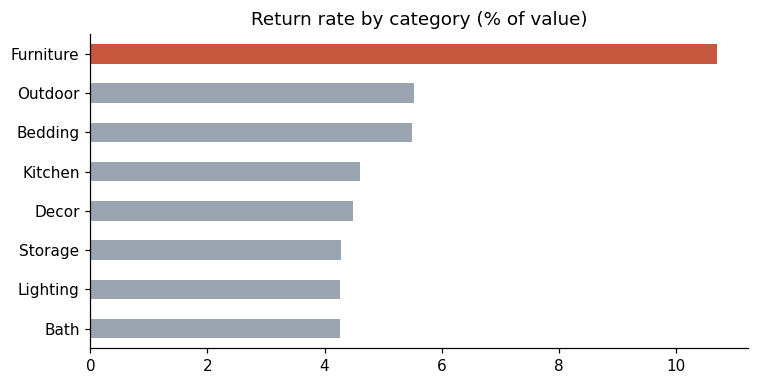

In [ ]:
rates = category["return_rate"].mul(100).sort_values()
ax = rates.plot.barh(color=["#C8553D" if c == "Furniture" else "#9AA5B1" for c in rates.index], figsize=(7, 3.6))
ax.set(title="Return rate by category (% of value)", ylabel="")
plt.tight_layout()

## 6. Customers and channels

In [ ]:
completed_orders_by_customer = completed.groupby("customer_id")["order_id"].nunique()
revenue_by_customer = completed.groupby("customer_id")["revenue"].sum()
customers["completed_orders"] = customers["customer_id"].map(completed_orders_by_customer).fillna(0)
customers["revenue"] = customers["customer_id"].map(revenue_by_customer).fillna(0)
customers["is_buyer"] = customers["completed_orders"] > 0

channels = customers.groupby("acquisition_channel").agg(
    customers=("customer_id", "size"),
    buyers=("is_buyer", "sum"),
    repeat_buyers=("completed_orders", lambda s: (s >= 2).sum()),
    revenue=("revenue", "sum"),
)
channels["buyer_rate"] = channels["buyers"] / channels["customers"]
channels["repeat_rate"] = channels["repeat_buyers"] / channels["buyers"]
channels["revenue_per_customer"] = channels["revenue"] / channels["customers"]
channels["customer_share"] = channels["customers"] / channels["customers"].sum()
channels["revenue_share"] = channels["revenue"] / channels["revenue"].sum()
channels = channels.sort_values("revenue_per_customer", ascending=False)

channel_p = stats.chi2_contingency(pd.crosstab(customers["acquisition_channel"], customers["is_buyer"]))[1]
print(f"buyer rate differs across channels: p = {channel_p:.1e}")
channels.round(3)

buyer rate differs across channels: p = 3.2e-19


,customers,buyers,repeat_buyers,revenue,buyer_rate,repeat_rate,revenue_per_customer,customer_share,revenue_share
acquisition_channel,,,,,,,,,
referral,367,248,182,274073.91,0.676,0.734,746.795,0.102,0.146
organic_search,1230,741,493,773610.01,0.602,0.665,628.951,0.342,0.411
email,423,271,179,241943.34,0.641,0.661,571.970,0.118,0.129
paid_search,550,327,204,290406.11,0.595,0.624,528.011,0.153,0.154
affiliate,199,93,60,63545.06,0.467,0.645,319.322,0.055,0.034
paid_social,831,367,200,238395.85,0.442,0.545,286.878,0.231,0.127


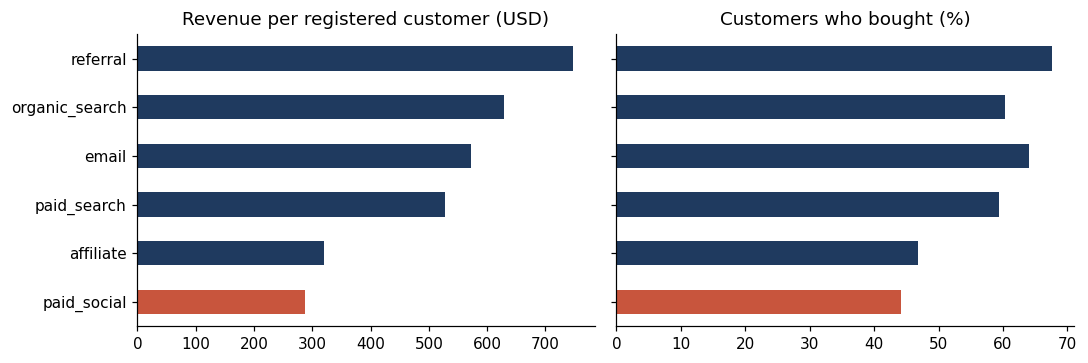

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
colors = ["#C8553D" if c == "paid_social" else "#1F3A5F" for c in channels.index]
channels["revenue_per_customer"].plot.barh(ax=axes[0], color=colors, title="Revenue per registered customer (USD)")
channels["buyer_rate"].mul(100).plot.barh(ax=axes[1], color=colors, title="Customers who bought (%)")
for ax in axes:
    ax.set_ylabel("")
axes[0].invert_yaxis()
plt.tight_layout()

In [ ]:
buyers = customers[customers["is_buyer"]].assign(
    segment=lambda d: pd.cut(
        d["completed_orders"],
        [0, 1, 4, POWER_MIN_ORDERS - 1, np.inf],
        labels=["One-time", "Occasional (2-4)", "Regular (5-14)", f"Power ({POWER_MIN_ORDERS}+)"],
    )
)
segments = buyers.groupby("segment", observed=True).agg(buyers=("customer_id", "size"), revenue=("revenue", "sum"))
segments["buyer_share"] = segments["buyers"] / segments["buyers"].sum()
segments["revenue_share"] = segments["revenue"] / segments["revenue"].sum()

sorted_revenue = buyers["revenue"].sort_values(ascending=False)
top_decile_share = sorted_revenue.head(len(sorted_revenue) // 10).sum() / sorted_revenue.sum()
never_ordered = (~customers["customer_id"].isin(orders["customer_id"])).sum()

print(f"top 10% of buyers: {top_decile_share:.1%} of revenue | registered customers who never ordered: {never_ordered:,} ({never_ordered / len(customers):.1%})")
segments.round(3)

top 10% of buyers: 44.2% of revenue | registered customers who never ordered: 1,494 (41.5%)


,buyers,revenue,buyer_share,revenue_share
segment,,,,
One-time,729,147564.97,0.356,0.078
Occasional (2-4),808,503621.00,0.395,0.268
Regular (5-14),429,737137.75,0.210,0.392
Power (15+),81,493650.56,0.040,0.262


## 7. Promotions

In [ ]:
promo = non_canceled.assign(code=non_canceled["discount_code"].fillna("None")).groupby("code").agg(
    orders=("order_id", "size"),
    discount=("discount", "sum"),
    net=("net", "sum"),
    cost=("cost", "sum"),
    first_order_share=("is_first_order", "mean"),
)
promo["margin"] = (promo["net"] - promo["cost"]) / promo["net"]

welcome = non_canceled[non_canceled["discount_code"] == "WELCOME10"]
welcome_first_share = welcome["is_first_order"].mean()
welcome_repeat_discount = welcome.loc[~welcome["is_first_order"], "discount"].sum()

print(f"WELCOME10 used on a first order: {welcome_first_share:.1%} | discount on repeat orders: ${welcome_repeat_discount:,.0f}")
promo.round(3)

WELCOME10 used on a first order: 27.3% | discount on repeat orders: $6,051


,orders,discount,net,cost,first_order_share,margin
code,,,,,,
HOLIDAY20,748,32000.71,127990.18,79428.24,0.225,0.379
None,7509,0.00,1752946.34,869694.55,0.230,0.504
SPRING15,233,7514.69,42582.24,24721.48,0.215,0.419
WELCOME10,373,8377.18,75392.59,41286.08,0.273,0.452


## 8. Power BI export

In [ ]:
active = {y: set(completed.loc[completed["year"] == y, "customer_id"]) for y in (2024, 2025)}
retention = len(active[2024] & active[2025]) / len(active[2024])
active_growth = len(active[2025]) / len(active[2024]) - 1
main_channels = channels.drop(["paid_social", "affiliate"])
ps, ref = channels.loc["paid_social"], channels.loc["referral"]
fur, hol, none = category.loc["Furniture"], promo.loc["HOLIDAY20"], promo.loc["None"]
vol_share, price_share = bridge["Volume & mix"] / bridge.sum(), bridge["Price increase"] / bridge.sum()

insight_cards = pd.DataFrame([
    {
        "id": 1, "tag": "Returns", "priority": "High",
        "question": "Which category sends the most orders back?",
        "headline": "Furniture",
        "subline": f"{line_return_rate[True]:.1%} of lines returned vs {line_return_rate[False]:.1%} elsewhere",
        "evidence": " | ".join([
            "The difference is statistically significant (p < 0.001)",
            f"{fur['returned_share']:.0%} of returned value from {fur['revenue_share']:.0%} of revenue",
            "NRF estimates about 19% of US online sales are returned (2025), so this is an internal outlier",
        ]),
        "action": "Capture return reasons; audit the five worst-return furniture products",
        "kpi": f"Furniture line return rate (now {line_return_rate[True]:.1%})",
        "limit": "No return reasons in the data, so causes are unknown",
    },
    {
        "id": 2, "tag": "Channels", "priority": "High",
        "question": "Which channel brings customers who rarely buy?",
        "headline": "Paid social",
        "subline": f"{ps['buyer_rate']:.0%} ever buy vs {main_channels['buyer_rate'].min():.0%}-{main_channels['buyer_rate'].max():.0%} in main channels",
        "evidence": " | ".join([
            f"{ps['customer_share']:.0%} of customers but {ps['revenue_share']:.0%} of revenue",
            f"Revenue per customer ${ps['revenue_per_customer']:,.0f} vs ${ref['revenue_per_customer']:,.0f} for referral",
            "Buyer rates differ across channels (p < 0.001)",
        ]),
        "action": "Pull channel spend, compute CAC and payback; test a referral incentive",
        "kpi": "Buyer rate and revenue per customer by channel",
        "limit": "No ad spend in the data, so profitability is unknown",
    },
    {
        "id": 3, "tag": "Growth", "priority": "Medium",
        "question": "What is driving 2025 growth?",
        "headline": f"+{growth:.1%}",
        "subline": f"{vol_share:.0%} volume and mix, {price_share:.0%} from the 5% price rise",
        "evidence": " | ".join([
            f"Active buyers up {active_growth:.0%}",
            f"{retention:.0%} of 2024 buyers bought again in 2025",
            f"Top 10% of buyers generate {top_decile_share:.0%} of revenue",
        ]),
        "action": "Track retention by signup cohort alongside revenue",
        "kpi": "12-month repeat rate by cohort",
        "limit": "Newer buyers have had less time to reorder",
    },
    {
        "id": 4, "tag": "Promotions", "priority": "Medium",
        "question": "Do holiday discounts pay off?",
        "headline": f"{hol['margin']:.1%} margin",
        "subline": f"HOLIDAY20 orders vs {none['margin']:.1%} without a code",
        "evidence": " | ".join([
            f"${hol['discount']:,.0f} in HOLIDAY20 discounts over two seasons",
            f"Only {hol['first_order_share']:.0%} of HOLIDAY20 orders are first orders",
            f"WELCOME10 is used on a first order only {welcome_first_share:.0%} of the time",
        ]),
        "action": "Run a holdout test before next November; limit WELCOME10 to one use",
        "kpi": "Incremental orders and margin versus holdout",
        "limit": "Without a control group the lift cannot be measured",
    },
])

dim_date = pd.DataFrame({"date": pd.date_range(orders["order_date"].min().normalize(), orders["order_date"].max().normalize())})
dim_date["year"] = dim_date["date"].dt.year
dim_date["month_number"] = dim_date["date"].dt.month
dim_date["month"] = dim_date["date"].dt.strftime("%b")
dim_date["year_month"] = dim_date["date"].dt.strftime("%Y-%m")

fact = lines.assign(order_date=lines["order_date"].dt.normalize())[[
    "order_id", "order_date", "customer_id", "product_id", "status", "discount_code",
    "payment_method", "quantity", "unit_price", "gross", "discount_amount", "net", "cost",
]]

export = Path("powerbi")
exports = {
    "fact_order_items": fact,
    "dim_customer": customers[["customer_id", "signup_date", "state", "acquisition_channel"]],
    "dim_product": products[["product_id", "product_name", "category", "list_price", "unit_cost"]],
    "dim_date": dim_date,
    "insight_cards": insight_cards,
    "card_side": pd.DataFrame({"side": ["Front", "Back"], "order": [1, 2]}),
}
for name, frame in exports.items():
    frame.to_csv(export / f"{name}.csv", index=False, date_format="%Y-%m-%d")

pd.Series({name: len(frame) for name, frame in exports.items()}, name="rows").to_frame()

,rows
fact_order_items,15608
dim_customer,3600
dim_product,90
dim_date,731
insight_cards,4
card_side,2


In [ ]:
check_values = pd.DataFrame([
    ("Net Revenue", revenue),
    ("Gross Profit", profit),
    ("Gross Margin", profit / revenue),
    ("Completed Orders", completed_orders),
    ("AOV", revenue / completed_orders),
    ("Return Rate Orders", order_return_rate),
    ("Revenue YoY 2025", growth),
    ("Furniture Return Rate Value", fur["return_rate"]),
    ("Paid Social Buyer Rate", ps["buyer_rate"]),
], columns=["measure", "expected"])
check_values.to_csv(export / "check_values.csv", index=False)
check_values.round(4)

,measure,expected
0,Net Revenue,1.881974e+06
1,Gross Profit,9.259483e+05
2,Gross Margin,4.920000e-01
3,Completed Orders,8.456000e+03
4,AOV,2.225608e+02
5,Return Rate Orders,4.590000e-02
6,Revenue YoY 2025,2.120000e-01
7,Furniture Return Rate Value,1.070000e-01
8,Paid Social Buyer Rate,4.416000e-01
